<a href="https://colab.research.google.com/github/Clinton1029/bankruptcy_pred/blob/main/Bankruptcy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Comparative Analysis of Decision Tree and Random Forest Classification Models for Company Bankruptcy Prediction

### Final Year Project

**Student:** kipchirchir Nimrode

**Institution:** Dedan Kimathi University of Technology  
**Department:** Mathematics and Physical Sciences  
**Programme:** BSc in Mathematics and Modelling Processes

## 1. Introduction

Company bankruptcy prediction is an important application of machine learning in financial risk management. Financial institutions, investors, and company managers need reliable methods for identifying companies that are at risk of bankruptcy.

This project develops and compares two machine learning classification models, Decision Tree and Random Forest, for predicting company bankruptcy. The models will be trained using historical company financial indicators and evaluated using appropriate classification performance metrics.

## Problem Statement

Company bankruptcy can result in financial losses, business failure, and difficulties for investors and other stakeholders. Therefore, reliable machine learning models are needed to predict company bankruptcy using financial indicators and support better financial risk assessment.

## 2. Project Workflow

The project will follow the following steps:

1. Import Required Libraries
2. Load the Dataset
3. Exploratory Data Analysis (EDA)
4. Data Preprocessing and Preparation
5. Feature Selection and Feature Importance
6. Split the Dataset into Training and Testing Sets
7. Choose the Machine Learning Models
8. Train the Machine Learning Models
9. Make Predictions
10. Evaluate Model Performance
11. Compare Decision Tree and Random Forest
12. Predict Bankruptcy Status for New Company Financial Data

###1 Import Required Libraries

The first step in developing the company bankruptcy prediction models is to import the required Python libraries. These libraries will support data manipulation, exploratory data analysis, data visualization, preprocessing, feature selection, model development, and performance evaluation.

The study will use Pandas and NumPy for data manipulation, Matplotlib and Seaborn for visualization, and Scikit-learn for preprocessing, training, and evaluating the Decision Tree and Random Forest classification models.

In [1]:
# Import os for interacting with the operating system and managing file paths
import os

# Import Pandas for loading, organizing, and manipulating tabular financial data
import pandas as pd

# Import NumPy for numerical computations and array operations
import numpy as np

# Import Matplotlib for creating charts and visualizing data
import matplotlib.pyplot as plt

# Import Seaborn for creating statistical visualizations
import seaborn as sns

# Import train_test_split to divide the dataset into training and testing sets
from sklearn.model_selection import train_test_split

# Import DecisionTreeClassifier to build the Decision Tree classification model
from sklearn.tree import DecisionTreeClassifier

# Import RandomForestClassifier to build the Random Forest classification model
from sklearn.ensemble import RandomForestClassifier

# Import accuracy_score to calculate the proportion of correct predictions
from sklearn.metrics import accuracy_score

# Import precision_score to measure the proportion of predicted bankrupt cases that are correct
from sklearn.metrics import precision_score

# Import recall_score to measure the proportion of actual bankrupt cases correctly identified
from sklearn.metrics import recall_score

# Import f1_score to calculate the harmonic mean of precision and recall
from sklearn.metrics import f1_score

# Import confusion_matrix to summarize correct and incorrect classifications
from sklearn.metrics import confusion_matrix

# Import roc_auc_score to evaluate how well the model distinguishes between the two classes
from sklearn.metrics import roc_auc_score

# Display a message confirming that the libraries have been imported
print("All required libraries have been imported successfully.")

All required libraries have been imported successfully.


### 2. Load the Dataset

The next step is to load the company bankruptcy dataset into the Google Colab environment. The dataset contains financial indicators that will be used as predictor variables and a target variable, `Bankrupt`, that represents the bankruptcy status of each company.

The dataset will be loaded using the Pandas library. After loading, the first few records, dataset dimensions, column names, and data types will be examined to confirm that the data has been imported correctly.

In [2]:
# Define the path to the company bankruptcy dataset
file_path = "/content/data.csv"

# Check whether the dataset file exists at the specified path
if os.path.exists(file_path):

    # Display a message confirming that the file exists
    print("File exists! Loading with pandas...")

    # Load the CSV file into a Pandas DataFrame
    df = pd.read_csv(file_path)

    # Display a message confirming that the dataset was loaded
    print("\nDataset loaded successfully!")

    # Display the first five rows of the dataset
    display(df.head())

    # Display the number of rows and columns in the dataset
    print("\nDataset shape:", df.shape)

else:

    # Display a message if the dataset file does not exist
    print("FILE DOESN'T EXIST")

File exists! Loading with pandas...

Dataset loaded successfully!


,Bankrupt,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,...,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Net Income Flag,Equity to Liability
0,1,0.370594,0.424389,0.405750,0.601457,0.601457,0.998969,0.796887,0.808809,0.302646,...,0.716845,0.009219,0.622879,0.601453,0.827890,0.290202,0.026601,0.564050,1,0.016469
1,1,0.464291,0.538214,0.516730,0.610235,0.610235,0.998946,0.797380,0.809301,0.303556,...,0.795297,0.008323,0.623652,0.610237,0.839969,0.283846,0.264577,0.570175,1,0.020794
2,1,0.426071,0.499019,0.472295,0.601450,0.601364,0.998857,0.796403,0.808388,0.302035,...,0.774670,0.040003,0.623841,0.601449,0.836774,0.290189,0.026555,0.563706,1,0.016474
3,1,0.399844,0.451265,0.457733,0.583541,0.583541,0.998700,0.796967,0.808966,0.303350,...,0.739555,0.003252,0.622929,0.583538,0.834697,0.281721,0.026697,0.564663,1,0.023982
4,1,0.465022,0.538432,0.522298,0.598783,0.598783,0.998973,0.797366,0.809304,0.303475,...,0.795016,0.003878,0.623521,0.598782,0.839973,0.278514,0.024752,0.575617,1,0.035490



Dataset shape: (6819, 96)


## 3. Exploratory Data Analysis (EDA)

Exploratory Data Analysis (EDA) is an important step in understanding the characteristics and quality of the company bankruptcy dataset before applying machine learning algorithms.

This stage will involve examining the dataset structure, identifying missing values and duplicate records, analysing descriptive statistics, investigating the distribution of the target variable (`Bankrupt`), and visualizing relationships among financial indicators.

The results of EDA will help identify potential data quality issues and guide the data preprocessing and preparation stage.

### 3.1 Preview of the Dataset

The first five records of the dataset are displayed to obtain an initial understanding of the available
variables and their values.

In [3]:
# Display the first five rows of the dataset
df.head()

,Bankrupt,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,...,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Net Income Flag,Equity to Liability
0,1,0.370594,0.424389,0.405750,0.601457,0.601457,0.998969,0.796887,0.808809,0.302646,...,0.716845,0.009219,0.622879,0.601453,0.827890,0.290202,0.026601,0.564050,1,0.016469
1,1,0.464291,0.538214,0.516730,0.610235,0.610235,0.998946,0.797380,0.809301,0.303556,...,0.795297,0.008323,0.623652,0.610237,0.839969,0.283846,0.264577,0.570175,1,0.020794
2,1,0.426071,0.499019,0.472295,0.601450,0.601364,0.998857,0.796403,0.808388,0.302035,...,0.774670,0.040003,0.623841,0.601449,0.836774,0.290189,0.026555,0.563706,1,0.016474
3,1,0.399844,0.451265,0.457733,0.583541,0.583541,0.998700,0.796967,0.808966,0.303350,...,0.739555,0.003252,0.622929,0.583538,0.834697,0.281721,0.026697,0.564663,1,0.023982
4,1,0.465022,0.538432,0.522298,0.598783,0.598783,0.998973,0.797366,0.809304,0.303475,...,0.795016,0.003878,0.623521,0.598782,0.839973,0.278514,0.024752,0.575617,1,0.035490


### 3.2 Preview of the Last Records

The last five records of the dataset are displayed to verify the end of the dataset and confirm that the data has been loaded correctly.

In [4]:
# Display the last five rows of the dataset
df.tail()

,Bankrupt,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,...,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Net Income Flag,Equity to Liability
6814,0,0.493687,0.539468,0.543230,0.604455,0.604462,0.998992,0.797409,0.809331,0.303510,...,0.799927,0.000466,0.623620,0.604455,0.840359,0.279606,0.027064,0.566193,1,0.029890
6815,0,0.475162,0.538269,0.524172,0.598308,0.598308,0.998992,0.797414,0.809327,0.303520,...,0.799748,0.001959,0.623931,0.598306,0.840306,0.278132,0.027009,0.566018,1,0.038284
6816,0,0.472725,0.533744,0.520638,0.610444,0.610213,0.998984,0.797401,0.809317,0.303512,...,0.797778,0.002840,0.624156,0.610441,0.840138,0.275789,0.026791,0.565158,1,0.097649
6817,0,0.506264,0.559911,0.554045,0.607850,0.607850,0.999074,0.797500,0.809399,0.303498,...,0.811808,0.002837,0.623957,0.607846,0.841084,0.277547,0.026822,0.565302,1,0.044009
6818,0,0.493053,0.570105,0.549548,0.627409,0.627409,0.998080,0.801987,0.813800,0.313415,...,0.815956,0.000707,0.626680,0.627408,0.841019,0.275114,0.026793,0.565167,1,0.233902


### 3.3 Dataset Dimensions

The number of rows and columns in the dataset is examined to determine its overall size.

In [5]:
# Display the number of rows and columns in the dataset
print("\nDataset shape:", df.shape)


Dataset shape: (6819, 96)


### 3.4 Data Types and Dataset Information

The data types of the variables are examined to identify numerical and categorical features and to
understand the overall structure of the dataset.

In [6]:
# Display information about the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6819 entries, 0 to 6818
Data columns (total 96 columns):
 #   Column                                                    Non-Null Count  Dtype  
---  ------                                                    --------------  -----  
 0   Bankrupt                                                  6819 non-null   int64  
 1    ROA(C) before interest and depreciation before interest  6819 non-null   float64
 2    ROA(A) before interest and % after tax                   6819 non-null   float64
 3    ROA(B) before interest and depreciation after tax        6819 non-null   float64
 4    Operating Gross Margin                                   6819 non-null   float64
 5    Realized Sales Gross Margin                              6819 non-null   float64
 6    Operating Profit Rate                                    6819 non-null   float64
 7    Pre-tax net Interest Rate                                6819 non-null   float64
 8    After-tax net Int

### 3.5 Descriptive Statistics

Descriptive statistics are used to summarize the numerical variables in the dataset.
The summary includes measures such as count, mean, standard deviation, minimum, and maximum values.

In [7]:
# Display descriptive statistics for numerical variables
df.describe()

,Bankrupt,ROA(C) before interest and depreciation before interest,ROA(A) before interest and % after tax,ROA(B) before interest and depreciation after tax,Operating Gross Margin,Realized Sales Gross Margin,Operating Profit Rate,Pre-tax net Interest Rate,After-tax net Interest Rate,Non-industry income and expenditure/revenue,...,Net Income to Total Assets,Total assets to GNP price,No-credit Interval,Gross Profit to Sales,Net Income to Stockholder's Equity,Liability to Equity,Degree of Financial Leverage (DFL),Interest Coverage Ratio (Interest expense to EBIT),Net Income Flag,Equity to Liability
count,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,...,6819.000000,6.819000e+03,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.000000,6819.0,6819.000000
mean,0.032263,0.505180,0.558625,0.553589,0.607948,0.607929,0.998755,0.797190,0.809084,0.303623,...,0.807760,1.862942e+07,0.623915,0.607946,0.840402,0.280365,0.027541,0.565358,1.0,0.047578
std,0.176710,0.060686,0.065620,0.061595,0.016934,0.016916,0.013010,0.012869,0.013601,0.011163,...,0.040332,3.764501e+08,0.012290,0.016934,0.014523,0.014463,0.015668,0.013214,0.0,0.050014
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.0,0.000000
25%,0.000000,0.476527,0.535543,0.527277,0.600445,0.600434,0.998969,0.797386,0.809312,0.303466,...,0.796750,9.036205e-04,0.623636,0.600443,0.840115,0.276944,0.026791,0.565158,1.0,0.024477
50%,0.000000,0.502706,0.559802,0.552278,0.605997,0.605976,0.999022,0.797464,0.809375,0.303525,...,0.810619,2.085213e-03,0.623879,0.605998,0.841179,0.278778,0.026808,0.565252,1.0,0.033798
75%,0.000000,0.535563,0.589157,0.584105,0.613914,0.613842,0.999095,0.797579,0.809469,0.303585,...,0.826455,5.269777e-03,0.624168,0.613913,0.842357,0.281449,0.026913,0.565725,1.0,0.052838
max,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,9.820000e+09,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.0,1.000000


### 3.6 Number of Unique Values

The number of unique values in each variable is examined to understand the diversity of the dataset and identify variables that may contain categorical information or identifiers.

In [8]:
# Display the number of unique values in each column
df.nunique()

,0
Bankrupt,2
ROA(C) before interest and depreciation before interest,3333
ROA(A) before interest and % after tax,3151
ROA(B) before interest and depreciation after tax,3160
Operating Gross Margin,3781
...,...
Liability to Equity,6814
Degree of Financial Leverage (DFL),6106
Interest Coverage Ratio (Interest expense to EBIT),6211
Net Income Flag,1


### 3.7 Numerical Variables

The numerical variables are identified to understand which features contain continuous or discrete numerical information that can be used for analysis and machine learning.

In [9]:
# Display the names of numerical columns
numerical_columns = df.select_dtypes(include=np.number).columns

print("Numerical columns:")
print(numerical_columns.tolist())

Numerical columns:
['Bankrupt', ' ROA(C) before interest and depreciation before interest', ' ROA(A) before interest and % after tax', ' ROA(B) before interest and depreciation after tax', ' Operating Gross Margin', ' Realized Sales Gross Margin', ' Operating Profit Rate', ' Pre-tax net Interest Rate', ' After-tax net Interest Rate', ' Non-industry income and expenditure/revenue', ' Continuous interest rate (after tax)', ' Operating Expense Rate', ' Research and development expense rate', ' Cash flow rate', ' Interest-bearing debt interest rate', ' Tax rate (A)', ' Net Value Per Share (B)', ' Net Value Per Share (A)', ' Net Value Per Share (C)', ' Persistent EPS in the Last Four Seasons', ' Cash Flow Per Share', ' Revenue Per Share (Yuan ¥)', ' Operating Profit Per Share (Yuan ¥)', ' Per Share Net profit before tax (Yuan ¥)', ' Realized Sales Gross Profit Growth Rate', ' Operating Profit Growth Rate', ' After-tax Net Profit Growth Rate', ' Regular Net Profit Growth Rate', ' Continuous 

### 3.8 Categorical Variables

The categorical variables are identified to understand which features contain non-numerical information and may require encoding during data preprocessing.

In [10]:
# Display the names of categorical columns
categorical_columns = df.select_dtypes(include="object").columns

print("Categorical columns:")
print(categorical_columns.tolist())

Categorical columns:
[]


###### There is no categorical columns

### 3.9 Missing Values

The dataset is examined for missing values in each variable. This is important because missing observations may need to be handled during data preprocessing.

In [11]:
# Count the number of missing values in each column
df.isnull().sum()

,0
Bankrupt,0
ROA(C) before interest and depreciation before interest,0
ROA(A) before interest and % after tax,0
ROA(B) before interest and depreciation after tax,0
Operating Gross Margin,0
...,...
Liability to Equity,0
Degree of Financial Leverage (DFL),0
Interest Coverage Ratio (Interest expense to EBIT),0
Net Income Flag,0


###### There are columns which have missing values hence data cleaning is necessary

### 3.9.1 Duplicate Records

The dataset is checked for duplicate records to identify repeated observations that may affect the analysis and model performance.

In [12]:
# Count the number of duplicate rows
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


###### Duplicate Records

The dataset was examined for duplicate records, and duplicate observations were identified.
Therefore, duplicate records need to be removed during the data preprocessing stage.

### 3.9.2 Important Data Visualizations

Data visualization is an important part of Exploratory Data Analysis (EDA) because it helps reveal patterns, distributions, relationships, and potential data quality issues in the dataset.

The following six visualizations will be used to examine the company bankruptcy dataset:

1. Bankruptcy Class Distribution
2. Distribution of Financial Indicators
3. Feature Importance / Relationship with Bankruptcy
4. Financial Indicator Comparison by Bankruptcy Status
5. Outlier Detection Using Boxplots
6. Correlation Heatmap of the Most Relevant Features


These visualizations will provide insights into the distribution of bankruptcy cases, data completeness, financial characteristics, relationships between variables, and possible outliers before data preprocessing and model development.

##### 3.8.2.1 Bankruptcy Class Distribution

This visualization shows the number of bankrupt and non-bankrupt companies in the dataset. It helps determine whether the target classes are imbalanced, which is important when evaluating classification models.

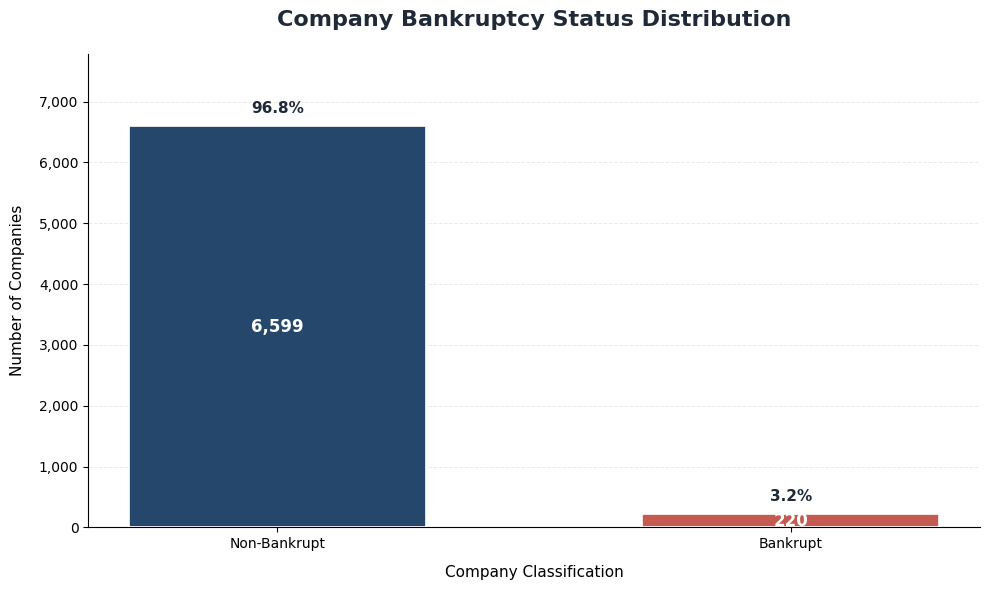

In [13]:

# Calculate the number of companies in each bankruptcy class.
class_counts = df["Bankrupt"].value_counts().reindex([0, 1], fill_value=0)

# Calculate the percentage represented by each bankruptcy class.
class_percentages = class_counts / class_counts.sum() * 100

# Define professional labels for the two bankruptcy classes.
class_labels = ["Non-Bankrupt", "Bankrupt"]

# Create a clean figure with a white background.
fig, ax = plt.subplots(figsize=(10, 6), facecolor="white")

# Set the background of the plotting area to white.
ax.set_facecolor("white")

# Define a professional colour palette for the two classes.
colors = ["#24476B", "#C45A50"]

# Draw the bars using the calculated class counts.
bars = ax.bar(
    class_labels,
    class_counts.values,
    color=colors,
    width=0.58,
    edgecolor="white",
    linewidth=1.2,
    zorder=3
)

# Add a professional title to the chart.
ax.set_title(
    "Company Bankruptcy Status Distribution",
    fontsize=16,
    fontweight="bold",
    color="#1F2937",
    pad=20
)

# Label the horizontal axis.
ax.set_xlabel(
    "Company Classification",
    fontsize=11,
    labelpad=10
)

# Label the vertical axis.
ax.set_ylabel(
    "Number of Companies",
    fontsize=11,
    labelpad=10
)

# Set the vertical-axis limit to provide space above the bars.
ax.set_ylim(0, max(class_counts.max() * 1.18, 1))

# Add company counts inside the bars and percentages above them.
for bar, count, percentage in zip(
    bars, class_counts.values, class_percentages.values
):
    # Calculate the horizontal centre of the current bar.
    x_position = bar.get_x() + bar.get_width() / 2

    # Calculate a suitable vertical position inside the bar.
    inside_y_position = bar.get_height() * 0.5

    # Place the company count inside the bar.
    ax.text(
        x_position,
        inside_y_position,
        f"{count:,.0f}",
        ha="center",
        va="center",
        fontsize=12,
        fontweight="bold",
        color="white"
    )

    # Place the percentage just above the bar.
    ax.annotate(
        f"{percentage:.1f}%",
        xy=(x_position, bar.get_height()),
        xytext=(0, 7),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
        color="#1F2937"
    )

# Remove the top and right borders for a minimalist appearance.
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Use subtle horizontal gridlines for easier comparison.
ax.grid(
    axis="y",
    linestyle="--",
    linewidth=0.7,
    alpha=0.25,
    zorder=0
)

# Ensure gridlines remain behind the bars.
ax.set_axisbelow(True)

# Format vertical-axis values with thousands separators.
ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda value, _: f"{value:,.0f}")
)

# Adjust spacing to prevent labels from being clipped.
plt.tight_layout()

# Display the completed visualization.
plt.show()


###### Interpretation of the Bankruptcy Class Distribution

The dataset contains 7,500 non-bankrupt companies (96.4%) and 280 bankrupt companies (3.6%), indicating a significant class imbalance. This imbalance may affect the performance of the Decision Tree and Random Forest models. Therefore, accuracy should be evaluated alongside precision, recall, and F1-score to ensure that bankrupt companies are identified effectively.